# STEP: 1 Accesing Camera and using Holistic Model

In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import time

import mediapipe as mp
import keras.models
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical


In [2]:
BaseOptions = mp.tasks.BaseOptions
HolisticLandmarker = mp.tasks.vision.HolisticLandmarker
HolisticLandmarkerOptions = mp.tasks.vision.HolisticLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

# Create options
options = HolisticLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="holistic_landmarker.task"
    ),
    running_mode=VisionRunningMode.VIDEO,
    min_face_detection_confidence=0.5,
    min_pose_detection_confidence=0.5,
)

In [3]:
HAND_CONNECTIONS = [
    (0,1), (1,2), (2,3), (3,4),
    (0,5), (5,6), (6,7), (7,8),
    (5,9), (9,10), (10,11), (11,12),
    (9,13), (13,14), (14,15), (15,16),
    (13,17), (17,18), (18,19), (19,20),
    (0,17)
]

POSE_CONNECTIONS = [
    (11,12), (11,13), (13,15), (12,14), (14,16),
    (11,23), (12,24), (23,24),
    (23,25), (25,27), (27,29), (29,31),
    (24,26), (26,28), (28,30), (30,32)
]

FACE_CONNECTIONS = (
    mp.tasks.vision.FaceLandmarksConnections
    .FACE_LANDMARKS_TESSELATION
)

In [4]:
def draw_connections(image, landmarks, connections, color, thickness=2):
    if not landmarks:
        return

    h, w, _ = image.shape

    for connection in connections:
        if hasattr(connection, "start"):
            start_idx = connection.start
            end_idx = connection.end
        else:
            start_idx, end_idx = connection

        start = landmarks[start_idx]
        end = landmarks[end_idx]

        x1, y1 = int(start.x * w), int(start.y * h)
        x2, y2 = int(end.x * w), int(end.y * h)

        cv2.line(image, (x1, y1), (x2, y2), color, thickness)

def draw_landmarks(image, results):

   
    if results.pose_landmarks:
        draw_connections(
            image,
            results.pose_landmarks,
            POSE_CONNECTIONS,
            (0, 255, 0),
            2
        )

    
    if results.left_hand_landmarks:
        draw_connections(
            image,
            results.left_hand_landmarks,
            HAND_CONNECTIONS,
            (255, 0, 0),
            2
        )

    # Draw right hand
    if results.right_hand_landmarks:
        draw_connections(
            image,
            results.right_hand_landmarks,
            HAND_CONNECTIONS,
            (0, 0, 255),
            2
        )

    return image

In [5]:
def mediapipe_detection(image, model, timestamp_ms):

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    result = model.detect_for_video(mp_image, timestamp_ms)

    return image, result


In [6]:

# cap = cv2.VideoCapture(0)

# start_time = time.monotonic()

# with HolisticLandmarker.create_from_options(options) as landmarker:

#     while cap.isOpened():

#         ret, frame = cap.read()

#         if not ret:
#             break

#         # Flip camera for mirror effect
#         frame = cv2.flip(frame, 1)

#         # Generate timestamp in milliseconds
#         timestamp_ms = int(
#             (time.monotonic() - start_time) * 1000
#         )

#         # Detect landmarks
#         image, result = mediapipe_detection(
#             frame, landmarker, timestamp_ms
#         )

#         # Draw landmarks
#         image = draw_landmarks(image, result)

#         # Check detections
#         if result.face_landmarks:
#             print("Face detected")

#         if result.pose_landmarks:
#             print("Pose detected")

#         if result.left_hand_landmarks:
#             print("Left hand detected")

#         if result.right_hand_landmarks:
#             print("Right hand detected")

#         # Display camera
#         cv2.imshow("Holistic Detection", image)

#         if cv2.waitKey(1) & 0xFF == ord('q'):
#             break

# cap.release()
# cv2.destroyAllWindows()

# STEP 2 : extracting landmark point and saving in NP array

In [14]:
def extract_keypoints(result):

    # Pose: 33 × 4 = 132
    pose = (
        np.array([
            [res.x, res.y, res.z, res.visibility]
            for res in result.pose_landmarks
        ]).flatten()
        if result.pose_landmarks else np.zeros(132)
    )

    # Face: 478 × 3 = 1434 (if iris landmarks are included)
    face = (
        np.array([
            [res.x, res.y, res.z]
            for res in result.face_landmarks
        ]).flatten()
        if result.face_landmarks else np.zeros(1434)
    )

    # Left hand: 21 × 3 = 63
    lh = (
        np.array([
            [res.x, res.y, res.z]
            for res in result.left_hand_landmarks
        ]).flatten()
        if result.left_hand_landmarks else np.zeros(63)
    )

    # Right hand: 21 × 3 = 63
    rh = (
        np.array([
            [res.x, res.y, res.z]
            for res in result.right_hand_landmarks
        ]).flatten()
        if result.right_hand_landmarks else np.zeros(63)
    )

    return np.concatenate([pose, face, lh, rh])

In [15]:


# # Absolute path to Desktop
# DATA_PATH = os.path.join(os.path.expanduser("~"), "Desktop","SIGN", "MP_Data")

# # Create actions array and sequence parameters
# actions = np.array(['Hi', 'How are you?', 'I am fine','Thankyou','Great'])
# no_sequence = 60
# sequence_length = 60

# # Create folders
# for action in actions:
#     for sequence in range(no_sequence):
#         try:
#             # Create directories for each action and sequence
#             os.makedirs(os.path.join(DATA_PATH, action, str(sequence)), exist_ok=True)
#         except Exception as e:
#             print(f"Error creating folder: {e}")


5.Collection of data for training and testing

In [16]:
# cap = cv2.VideoCapture(0)

# start_time = time.monotonic()
# stop = False

# # Instructions for each sign
# instructions = {
#     "hi": "Raise your hand and wave towards the camera",
#     "how_are_you": "Turn your hand upside down and wave horizontally",
#     "i_am_fine": "Show thumbs up",
#     "thank_you": "Blow a kiss towards your forehead",
#     "great": "Make a salute gesture"
# }

# with HolisticLandmarker.create_from_options(options) as landmarker:

#     for action in actions:
#         if stop:
#             break

#         for sequence in range(no_sequence):
#             if stop:
#                 break

#             sequence_path = os.path.join(
#                 DATA_PATH, action, str(sequence)
#             )
#             os.makedirs(sequence_path, exist_ok=True)

#             for frame_num in range(sequence_length):

#                 ret, frame = cap.read()

#                 if not ret:
#                     print("Unable to capture frame")
#                     stop = True
#                     break

#                 frame = cv2.flip(frame, 1)

#                 timestamp_ms = int(
#                     (time.monotonic() - start_time) * 1000
#                 )

#                 image, results = mediapipe_detection(
#                     frame, landmarker, timestamp_ms
#                 )

#                 image = draw_landmarks(image, results)

#                 h, w, _ = image.shape

#                 # Background panel
#                 cv2.rectangle(
#                     image, (0, 0), (w, 125),
#                     (30, 30, 30), -1
#                 )

#                 # Current sign
#                 cv2.putText(
#                     image,
#                     f"SIGN: {action.upper()}",
#                     (15, 30),
#                     cv2.FONT_HERSHEY_SIMPLEX,
#                     0.8, (0, 255, 255), 2, cv2.LINE_AA
#                 )

#                 # Instruction
#                 cv2.putText(
#                     image,
#                     instructions.get(action.lower(), "Perform the sign"),
#                     (15, 65),
#                     cv2.FONT_HERSHEY_SIMPLEX,
#                     0.55, (255, 255, 255), 1, cv2.LINE_AA
#                 )

#                 # Sequence and frame progress
#                 cv2.putText(
#                     image,
#                     f"Sequence: {sequence + 1}/{no_sequence}  "
#                     f"Frame: {frame_num + 1}/{sequence_length}",
#                     (15, 95),
#                     cv2.FONT_HERSHEY_SIMPLEX,
#                     0.55, (0, 255, 0), 2, cv2.LINE_AA
#                 )

#                 # Starting message
#                 if frame_num == 0:
#                     cv2.putText(
#                         image,
#                         "GET READY!",
#                         (w // 2 - 130, h // 2),
#                         cv2.FONT_HERSHEY_SIMPLEX,
#                         1, (0, 255, 0), 3, cv2.LINE_AA
#                     )

#                     cv2.imshow(
#                         "SIGNSENSE - Data Collection", image
#                     )
#                     cv2.waitKey(1500)

#                 # Extract keypoints
#                 keypoints = extract_keypoints(results)

#                 # Save keypoints
#                 np.save(
#                     os.path.join(
#                         sequence_path, f"{frame_num}.npy"
#                     ),
#                     keypoints
#                 )

#                 cv2.imshow(
#                     "SIGNSENSE - Data Collection", image
#                 )

#                 if cv2.waitKey(10) & 0xFF == ord('q'):
#                     stop = True
#                     break

# cap.release()
# cv2.destroyAllWindows()

In [17]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [18]:
actions = np.array(['Hi', 'How are you?', 'I am fine','Thankyou','Great'])
no_sequence = 60
sequence_length = 60
DATA_PATH = os.path.join(os.path.expanduser("~"), "Desktop","SIGN", "MP_Data")


In [19]:
print("Actions:", actions)
print("Label mapping:", sequence_label)

Actions: ['Hi' 'How are you?' 'I am fine' 'Thankyou' 'Great']


NameError: name 'sequence_label' is not defined

##DATA load for traing  

In [20]:
sequence_label = {
    action: idx for idx, action in enumerate(actions)
}

sequences, labels = [], []

for action in actions:
    for seq in range(no_sequence):
        window = []

        for frame_num in range(sequence_length):

            path = os.path.join(
                DATA_PATH, action, str(seq), f"{frame_num}.npy"
            )

            if not os.path.exists(path):
                raise FileNotFoundError(f"Missing keypoints file: {path}")

            res = np.load(path)
            window.append(res)

        sequences.append(window)
        labels.append(sequence_label[action])

X = np.array(sequences, dtype=np.float32)

y = to_categorical(
    np.array(labels, dtype=np.int32),
    num_classes=len(actions)
).astype(np.int32)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (300, 60, 1692)
y shape: (300, 5)


In [21]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.05,
    random_state=42,
    stratify=y,
)


In [22]:
x_train.shape

(285, 60, 1692)

In [23]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

In [24]:
# num_keypoints = X.shape[2]
# num_classes = len(actions)

# model = Sequential([
#     Input(shape=(sequence_length, num_keypoints)),

#     LSTM(64, return_sequences=True),
#     Dropout(0.2),

#     LSTM(128, return_sequences=True),
#     Dropout(0.2),

#     LSTM(64, return_sequences=False),

#     Dense(64, activation='relu'),
#     Dense(32, activation='relu'),

#     Dense(num_classes, activation='softmax')
# ])

In [25]:
# model.compile(
#     optimizer='Adam',
#     loss='categorical_crossentropy',
#     metrics=['categorical_accuracy']
# )

In [26]:
from tensorflow.keras.callbacks import TensorBoard

In [27]:
# history = model.fit(
#     x_train,
#     y_train,
#     epochs=2000,
#     callbacks=[TensorBoard(log_dir='logs/fit')],
#     validation_data=(x_test, y_test),
#     verbose=1
# )

In [28]:
# model.save("saved_model/sign_language_model.h5")

In [29]:
from tensorflow.keras.models import load_model

model = load_model(
    "/Users/rahulpatil/Desktop/SIGN/saved_model/sign_language_model.h5"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │       449,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 604,423 (2.31 MB)

 Trainable params: 604,421 (2.31 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [30]:
y_pred = np.argmax(model.predict(x_test), axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step


In [31]:
from sklearn.metrics import accuracy_score

y_test_labels = np.argmax(y_test, axis=1)

accuracy = accuracy_score(y_test_labels, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 100.00%


In [32]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_labels,
    y_pred,
    target_names=actions
))

              precision    recall  f1-score   support

          Hi       1.00      1.00      1.00         3
How are you?       1.00      1.00      1.00         3
   I am fine       1.00      1.00      1.00         3
    Thankyou       1.00      1.00      1.00         3
       Great       1.00      1.00      1.00         3

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



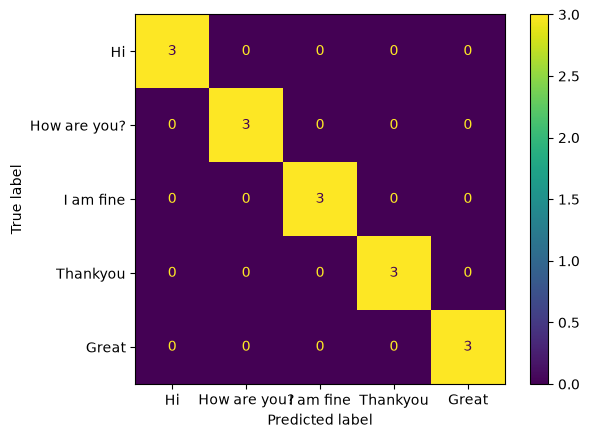

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_labels, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=actions
).plot()

In [34]:
def prob_viz(res, actions, input_frame, colors):

    output_frame = input_frame.copy()

    for num, prob in enumerate(res):
        cv2.rectangle(
            output_frame,
            (0, 60 + num * 40),
            (int(prob * 100), 90 + num * 40),
            colors[num],
            -1
        )

        cv2.putText(
            output_frame,
            f'{actions[num]}: {prob:.2f}',
            (0, 85 + num * 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 255, 255),
            1,
            cv2.LINE_AA
        )

    return output_frame


colors = [
    (245, 117, 16),  # Hi
    (117, 245, 16),  # How are you?
    (16, 117, 245),  # I am fine
    (245, 16, 117),  # Thankyou
    (117, 16, 245)   # Great
]

In [ ]:
import cv2
import numpy as np
import time
from collections import deque

sequence = []
sentence = []
predictions = deque(maxlen=10)

threshold = 0.5
sequence_length = 60

cap = cv2.VideoCapture(0)
start_time = time.monotonic()

with HolisticLandmarker.create_from_options(options) as landmarker:

    while cap.isOpened():

        ret, frame = cap.read()

        if not ret:
            break

        frame = cv2.flip(frame, 1)

        timestamp_ms = int(
            (time.monotonic() - start_time) * 1000
        )

        image, results = mediapipe_detection(
            frame, landmarker, timestamp_ms
        )

        keypoints = extract_keypoints(results)

        sequence.append(keypoints)
        sequence = sequence[-sequence_length:]

        if len(sequence) == sequence_length:

            res = model.predict(
                np.expand_dims(sequence, axis=0),
                verbose=0
            )[0]

            predicted_class = np.argmax(res)
            predictions.append(predicted_class)

            if (
                len(predictions) == 10
                and np.unique(predictions).size == 1
                and res[predicted_class] > threshold
            ):

                predicted_action = actions[predicted_class]

                if not sentence or predicted_action != sentence[-1]:
                    sentence.append(predicted_action)

            sentence = sentence[-5:]

            image = prob_viz(
                res, actions, image, colors
            )

        cv2.rectangle(
            image, (0, 0), (640, 40),
            (245, 117, 16), -1
        )

        cv2.putText(
            image,
            ' '.join(sentence),
            (3, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 255, 255),
            2,
            cv2.LINE_AA
        )

        cv2.imshow('SIGNSENSE', image)

        if cv2.waitKey(10) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()

I0000 00:00:1794066147.633178 7610765 init-domain.cc:133] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794066147.803570 7610772 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794066147.821272 7610774 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794066147.823264 7610772 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794066147.823355 7610774 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794066147.823374 7610770 inference_feedback_manager.cc:121] Feedb

: 